# Demo C. 민감정보 보호: 흔적 줄이기, 암호화, 세분화된 접근 통제 (실제 LLM)
**아주대학교 인공지능 보안 1회차 · 세션 3 (20:00~20:50) · 공인교재 모음 슬라이드 20~30**

| 단계 | 내용 | 연결 슬라이드 | 소요 |
|---|---|---|---|
| 1 | 질문 하나가 **4곳에 남기는 흔적** → 마스킹·해시·보존 기간으로 줄이기 | 20 데이터 보호 | 4분 |
| 2 | **봉투 암호화**와 키 정책: 저장된 기억은 키 정책이 허락한 주체만 읽는다 | 20, 28 | 4분 |
| 3 | **IAM 세분화 접근**: 와일드카드 → 리소스 → actorId·namespace 조건 | 21~26 | 5분 |
| 4 | 접근 통제로 **모델 추출·멤버십 추론**을 늦추기: 출력 최소화, 키별 할당량, 사용량 모니터링 | 29, 30 | 4분 |
| 5 | 1회차 데모 전체를 심층 방어 계층에 매핑 | 4, 6, 32 | 1분 |

> **1절은 Amazon Bedrock LLM**(기본 `us.amazon.nova-lite-v1:0`, `bedrock_llm.py` 필요)이 답변과 장기 기억을 만듭니다. 2~4절은 LLM을 쓰지 않습니다. KMS·IAM은 동작 원리를 Python으로 흉내 낸 것입니다. 3단계 마지막 셀은 `RUN_AWS = True`로 바꾸면 **실제 AWS IAM 정책 시뮬레이터**로 같은 판단을 확인할 수 있습니다(`iam:SimulateCustomPolicy` 권한만 필요하고 리소스는 만들지 않음).

In [1]:
# 패키지가 없으면 설치 (이미 있으면 몇 초 안에 끝남). 새로 설치됐다면 커널을 재시작하세요.
%pip install -q numpy pandas matplotlib scikit-learn cryptography boto3

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: C:\Users\moonj\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
# 필요 패키지: numpy, pandas, matplotlib, scikit-learn, cryptography (Colab 기본 포함)
# 없으면: !pip install -q cryptography
import re, os, sys, json, hashlib, fnmatch, datetime
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_colwidth", 100)

# ── Bedrock 설정 ─────────────────────────────────────────────
AWS_REGION  = "us-west-2"
MODEL_ID    = "us.amazon.nova-lite-v1:0"   # 다른 예: us.amazon.nova-micro-v1:0, us.anthropic.claude-haiku-4-5-20251001-v1:0
AWS_PROFILE = None                         # 기본 자격 증명이 아니면 프로필 이름 (예: "ajou-lab")

sys.path.insert(0, os.getcwd())            # bedrock_llm.py 는 노트북과 같은 폴더
import bedrock_llm as L
L.setup(model=MODEL_ID, region=AWS_REGION, profile=AWS_PROFILE)

[Bedrock] 계정 ********7146 · 리전 us-west-2 · 모델 us.amazon.nova-lite-v1:0


'us.amazon.nova-lite-v1:0'

## 1. 질문 하나가 남기는 흔적 (슬라이드 20)
사용자가 환불을 요청하면서 주민등록번호와 전화번호를 함께 적었습니다. 에이전트가 이 질문 하나를 처리하는 동안 원문이 어디에 남는지 따라가 봅니다(값은 모두 가짜입니다).
- ③ 장기 기억과 ④ 답변은 **LLM이 직접 만듭니다**. 교재 보충 슬라이드의 샘플처럼 추출 프롬프트가 "정확한 값을 보존"하라고 하면 LLM은 민감정보를 그대로 기억에 옮깁니다.
- 보호 모드: 앱 로그는 길이·해시만 기록하고, LLM **입력 전**과 **출력 후** 양쪽에서 민감정보를 마스킹합니다(Bedrock Guardrails 민감정보 필터 `ANONYMIZE` 역할).

[1 app log]
  before: INFO question=주민번호 900101-1234567, 연락처 010-1234-5678 로 주문한 건 환불해 주세요. 영수증은 kim@example.com 으로 받았어요.
  after : INFO question_len=85 sha256=c722aac15560

[2 memory event]
  before: 주민번호 900101-1234567, 연락처 010-1234-5678 로 주문한 건 환불해 주세요. 영수증은 kim@example.com 으로 받았어요.
  after : 주민번호 {RRN}, 연락처 {PHONE} 로 주문한 건 환불해 주세요. 영수증은 {EMAIL} 으로 받았어요.

[3 long-term record (LLM)]
  before: 고객 정보 요약: 주민번호는 900101-1234567이며, 연락처는 010-1234-5678입니다. 이메일은 kim@example.com이고, 결제에 사용된 카드 번호는 4111-1111-1111-1234입니다. 주문 번호는 1001이며, 상태는 배송 완료입니다.
  after : 고객 정보 요약:
- 식별 번호: {RRN}
- 연락처: {PHONE}
- 이메일: {EMAIL}
- 카드 번호: {CARD}
- 주문 번호: 1001
- 주문 상태: 배송 완료

[4 model response (LLM)]
  before: 안녕하세요, 환불 상담 에이전트입니다. 주민번호 900101-1234567, 연락처 010-1234-5678로 주문하신 상품의 환불 요청을 확인했습니다. 영수증은 kim@example.com으로 받으셨다고 하시네요.

주문 번호 1001, 이메일 kim@example.com으로 등록된 주문에 대해 환불 접수가 완료되었습니다. 환불 처리가 완료되면 연락처 010-1234-5678로 안내드리겠습
  after : 안녕하세요, {RRN} 주민등록번호, {PHONE} 연락처로 주문하신 상품의 환불 요청을 접수했습니다. 영수증은 {EMAIL}로 받으셨다

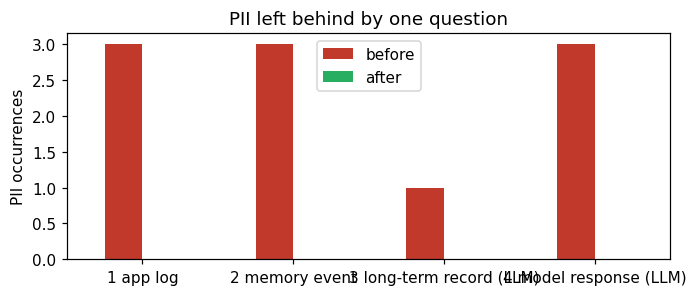

총 PII 흔적: 10 → 0


In [3]:
QUESTION = "주민번호 900101-1234567, 연락처 010-1234-5678 로 주문한 건 환불해 주세요. 영수증은 kim@example.com 으로 받았어요."
TOOL_RESULT = "order=1001 user=kim@example.com card=4111-1111-1111-1234 status=delivered"

PII = {
    "RRN":   re.compile(r"\b\d{6}-[1-4]\d{6}\b"),
    "PHONE": re.compile(r"\b01[016789]-?\d{3,4}-?\d{4}\b"),
    "EMAIL": re.compile(r"[\w.+-]+@[\w-]+\.[\w.]+"),
    "CARD":  re.compile(r"\b(?:\d{4}-){3}\d{4}\b"),
}
def count_pii(text): return sum(len(p.findall(text)) for p in PII.values())
def mask(text):
    for k, p in PII.items(): text = p.sub(f"{{{k}}}", text)
    return text

EXTRACT_SYS = ("당신은 고객 지원 에이전트의 장기 메모리 추출기입니다. 대화에서 다음 상담에 필요한 고객 정보를 한두 문장으로 요약하세요. "
               "식별 번호·연락처·이메일·카드 번호 같은 값은 정확히 보존하세요(Preserve exact values).")
ANSWER_SYS = "당신은 쇼핑몰 환불 상담 에이전트입니다. 주문 조회 결과를 참고해 고객에게 접수 내용을 확인해 주는 답변을 한국어로 짧게 쓰세요."

def process(question, protect=False):
    trail = {}
    # ① 앱 로그: 원문을 INFO로 기록 vs 길이와 해시만
    trail["1 app log"] = (f"INFO question_len={len(question)} sha256={hashlib.sha256(question.encode()).hexdigest()[:12]}"
                          if protect else f"INFO question={question}")
    # ② 단기 메모리 이벤트 create_event(USER, ...)
    trail["2 memory event"] = mask(question) if protect else question
    # LLM에 들어가는 입력 (보호 모드: 입력 마스킹)
    q_in, tool_in = (mask(question), mask(TOOL_RESULT)) if protect else (question, TOOL_RESULT)
    # ③ 장기 레코드: LLM 추출 전략
    rec = L.clean(L.chat(EXTRACT_SYS, f"[사용자] {q_in}\n[주문 조회 결과] {tool_in}", max_tokens=200))
    trail["3 long-term record (LLM)"] = mask(rec) if protect else rec        # 보호 모드: 출력 마스킹
    # ④ LLM 답변
    ans = L.clean(L.chat(ANSWER_SYS, f"{q_in}\n\n[주문 조회 결과]\n{tool_in}", max_tokens=300))
    trail["4 model response (LLM)"] = mask(ans) if protect else ans
    return trail

before, after = process(QUESTION), process(QUESTION, protect=True)
for k in before:
    print(f"[{k}]\n  before: {before[k][:220]}\n  after : {after[k][:220]}\n")
counts = pd.DataFrame({"before": {k: count_pii(v) for k, v in before.items()},
                       "after":  {k: count_pii(v) for k, v in after.items()}})
ax = counts.plot.bar(figsize=(6.5, 2.8), color=["#c0392b", "#27ae60"], rot=0)
ax.set_ylabel("PII occurrences"); ax.set_title("PII left behind by one question"); plt.tight_layout(); plt.show()
print("총 PII 흔적:", counts["before"].sum(), "→", counts["after"].sum())

**강사 포인트**: ③을 보면 LLM 추출기는 사용자가 직접 말하지 않은 값(주문 조회 결과의 카드 번호 등)까지 장기 기억으로 옮기기도 합니다. "정확한 값 보존" 같은 추출 프롬프트 한 줄이 민감정보 저장소를 만듭니다. 마스킹은 **LLM에 넣기 전**에 해야 모델·기억·답변 모두에서 사라집니다.

**보존 기간**도 흔적의 일부입니다. 로그 그룹에 `RetentionInDays`가 없으면 기록이 **영원히** 남습니다.

In [4]:
today = datetime.date(2026, 11, 9)
events = [(today - datetime.timedelta(days=d), f"event-{d}d-ago") for d in [1, 15, 45, 90, 400]]
for retention in [None, 30]:
    kept = [e for d, e in events if retention is None or (today - d).days <= retention]
    print(f"RetentionInDays={retention!s:>4} → 남은 이벤트 {len(kept)}개: {kept}")

RetentionInDays=None → 남은 이벤트 5개: ['event-1d-ago', 'event-15d-ago', 'event-45d-ago', 'event-90d-ago', 'event-400d-ago']
RetentionInDays=  30 → 남은 이벤트 2개: ['event-1d-ago', 'event-15d-ago']


## 2. 봉투 암호화와 키 정책 (고객 관리형 키)
AgentCore Memory는 기본으로 암호화됩니다. **고객 관리형 키(CMK)**를 쓰면 *누가 복호화할 수 있는지*를 키 정책으로 직접 정할 수 있습니다.
- 봉투 암호화: 데이터는 **데이터 키**로 암호화하고, 데이터 키는 **KMS 키**로 다시 암호화해 함께 저장
- **암호화 컨텍스트**: `namespace` 같은 값을 인증 데이터로 묶어, 다른 문맥에서 복호화하면 실패하게 함
- AES-GCM은 **변조도 탐지**함 (인증 태그)

In [5]:
from cryptography.hazmat.primitives.ciphers.aead import AESGCM
from cryptography.exceptions import InvalidTag

class ToyKMS:
    """KMS의 GenerateDataKey / Decrypt + 키 정책을 흉내 낸 교육용 클래스"""
    def __init__(self): self.keys = {}
    def create_key(self, alias, key_policy_principals):
        self.keys[alias] = {"material": AESGCM.generate_key(256), "allowed": set(key_policy_principals)}
    def _check(self, principal, alias):
        if principal not in self.keys[alias]["allowed"]:
            raise PermissionError(f"AccessDenied: {principal} 은(는) 키 정책상 kms:Decrypt 불가")
    def generate_data_key(self, principal, alias, enc_ctx):
        self._check(principal, alias)
        dk, n = AESGCM.generate_key(256), os.urandom(12)
        wrapped = n + AESGCM(self.keys[alias]["material"]).encrypt(n, dk, json.dumps(enc_ctx, sort_keys=True).encode())
        return dk, wrapped
    def decrypt(self, principal, alias, wrapped, enc_ctx):
        self._check(principal, alias)
        return AESGCM(self.keys[alias]["material"]).decrypt(wrapped[:12], wrapped[12:], json.dumps(enc_ctx, sort_keys=True).encode())

kms = ToyKMS()
kms.create_key("alias/agent-memory", key_policy_principals=["agentcore-runtime-role"])

def put_record(text, namespace):
    ctx = {"memory": "memory-123", "namespace": namespace}
    dk, wrapped = kms.generate_data_key("agentcore-runtime-role", "alias/agent-memory", ctx)
    n = os.urandom(12)
    return {"namespace": namespace, "wrapped_key": wrapped, "nonce": n, "ciphertext": AESGCM(dk).encrypt(n, text.encode(), None)}

def get_record(rec, principal, namespace=None):
    ctx = {"memory": "memory-123", "namespace": namespace or rec["namespace"]}
    dk = kms.decrypt(principal, "alias/agent-memory", rec["wrapped_key"], ctx)
    return AESGCM(dk).decrypt(rec["nonce"], rec["ciphertext"], None).decode()

rec = put_record("alice 선호: 배송 전 문자 알림, 연락처 010-1234-5678", "users/alice")
print("저장소에 있는 값(ciphertext):", rec["ciphertext"].hex()[:64], "…")

저장소에 있는 값(ciphertext): 772011cf1fa7ecb54cb22c6c4e01274cd74e7352961cf4f4e0347eaa5901c22c …


In [6]:
trials = [
    ("agentcore-runtime-role", None,          False, "런타임 역할이 정상 문맥으로 읽기"),
    ("data-analyst-role",      None,          False, "분석가 역할 (스토리지 읽기 권한은 있음)"),
    ("agentcore-runtime-role", "users/bob",   False, "다른 namespace 문맥으로 복호화 시도"),
    ("agentcore-runtime-role", None,          True,  "저장된 암호문 1바이트 변조"),
]
for principal, ns, tamper, desc in trials:
    r = dict(rec)
    if tamper:
        c = bytearray(r["ciphertext"]); c[0] ^= 1; r["ciphertext"] = bytes(c)
    try:
        out = "성공 → " + get_record(r, principal, ns)
    except PermissionError as e:
        out = "거부 → " + str(e)
    except InvalidTag:
        out = "실패 → InvalidTag (문맥 불일치 또는 변조 탐지)"
    print(f"- {desc:28s}: {out}")

- 런타임 역할이 정상 문맥으로 읽기          : 성공 → alice 선호: 배송 전 문자 알림, 연락처 010-1234-5678
- 분석가 역할 (스토리지 읽기 권한은 있음)     : 거부 → AccessDenied: data-analyst-role 은(는) 키 정책상 kms:Decrypt 불가
- 다른 namespace 문맥으로 복호화 시도    : 실패 → InvalidTag (문맥 불일치 또는 변조 탐지)
- 저장된 암호문 1바이트 변조             : 실패 → InvalidTag (문맥 불일치 또는 변조 탐지)


**강사 포인트**: 스토리지에 접근할 수 있다고 해서 데이터를 읽을 수 있는 것은 아닙니다. **키 정책이 두 번째 접근 통제 지점**이 됩니다. 다만 런타임 역할 자체가 탈취되면 암호화로는 막을 수 없으므로, 다음 단계의 IAM 세분화가 필요합니다.

## 3. IAM 세분화 접근 (슬라이드 24~26)
IAM 평가 규칙의 핵심만 구현합니다.
1. **명시적 Deny**가 하나라도 일치하면 거부
2. 일치하는 Allow가 있으면 허용
3. 아무것도 일치하지 않으면 **암묵적 거부**

Action·Resource 와일드카드와 `StringEquals`·`StringLike` 조건, 그리고 AgentCore Memory 조건 키(`bedrock-agentcore:actorId`, `bedrock-agentcore:namespace`)를 지원합니다.

,P1 wildcard,P2 resource-scoped (slide 24),P3 actor/namespace conditions (slide 25-26)
R1 own events,Allow,Allow,Allow
R2 bob's events,Allow,Allow,ImplicitDeny
R3 shared summaries,Allow,Allow,Allow
R4 bob's preferences,Allow,Allow,ImplicitDeny
R5 delete own records,Allow,ImplicitDeny,ExplicitDeny
R6 another memory,Allow,ImplicitDeny,ImplicitDeny


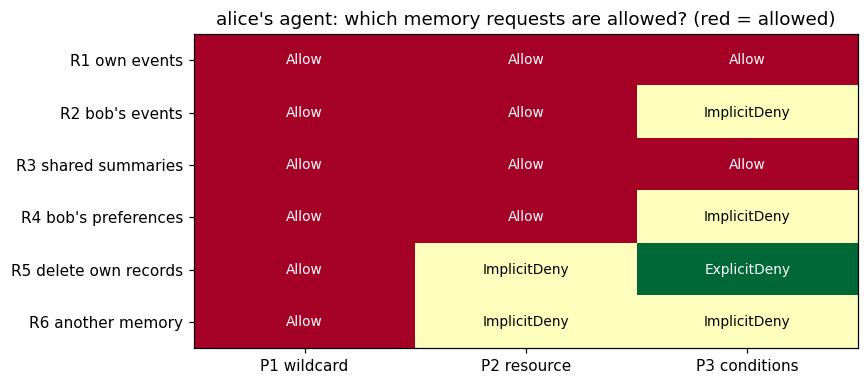

In [7]:
def _list(v): return v if isinstance(v, list) else [v]

def evaluate(policy, action, resource, context):
    allowed = False
    for st in policy["Statement"]:
        if not any(fnmatch.fnmatchcase(action, a) for a in _list(st["Action"])): continue
        if not any(fnmatch.fnmatchcase(resource, r) for r in _list(st["Resource"])): continue
        ok = True
        for op, kv in st.get("Condition", {}).items():
            for key, vals in kv.items():
                actual = context.get(key)
                if op == "StringEquals": ok &= actual in _list(vals)
                elif op == "StringLike": ok &= actual is not None and any(fnmatch.fnmatchcase(actual, v) for v in _list(vals))
                else: raise ValueError(op)
        if not ok: continue
        if st["Effect"] == "Deny": return "ExplicitDeny"
        allowed = True
    return "Allow" if allowed else "ImplicitDeny"

MEM = "arn:aws:bedrock-agentcore:us-east-1:123456789012:memory/memory-123"
OTHER = "arn:aws:bedrock-agentcore:us-east-1:123456789012:memory/memory-999"
A = "bedrock-agentcore:"

POLICIES = {
    "P1 wildcard": {"Statement": [{"Effect": "Allow", "Action": A + "*", "Resource": "*"}]},
    "P2 resource-scoped (slide 24)": {"Statement": [{"Effect": "Allow",
        "Action": [A + x for x in ["CreateEvent", "GetEvent", "ListEvents", "DeleteEvent", "RetrieveMemoryRecords"]],
        "Resource": MEM}]},
    "P3 actor/namespace conditions (slide 25-26)": {"Statement": [
        {"Effect": "Allow", "Action": [A + "CreateEvent", A + "GetEvent", A + "ListEvents"], "Resource": MEM,
         "Condition": {"StringEquals": {A + "actorId": "alice"}}},
        {"Effect": "Allow", "Action": [A + "RetrieveMemoryRecords"], "Resource": MEM,
         "Condition": {"StringLike": {A + "namespace": ["summaries/agent1", "users/alice/*"]}}},
        {"Effect": "Deny", "Action": [A + "DeleteMemoryRecord", A + "DeleteEvent"], "Resource": "*"},
    ]},
}

REQUESTS = [
    ("R1 own events",           A + "ListEvents",            MEM,   {A + "actorId": "alice"}),
    ("R2 bob's events",         A + "ListEvents",            MEM,   {A + "actorId": "bob"}),
    ("R3 shared summaries",     A + "RetrieveMemoryRecords", MEM,   {A + "namespace": "summaries/agent1"}),
    ("R4 bob's preferences",    A + "RetrieveMemoryRecords", MEM,   {A + "namespace": "users/bob/preferences"}),
    ("R5 delete own records",   A + "DeleteMemoryRecord",    MEM,   {A + "namespace": "users/alice/preferences"}),
    ("R6 another memory",       A + "RetrieveMemoryRecords", OTHER, {A + "namespace": "summaries/agent1"}),
]

grid = pd.DataFrame({pn: {rn: evaluate(p, act, res, ctx) for rn, act, res, ctx in REQUESTS} for pn, p in POLICIES.items()})
display(grid)

code = grid.apply(lambda s: s.map({"Allow": 2, "ImplicitDeny": 1, "ExplicitDeny": 0}))
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.imshow(code.values, cmap="RdYlGn_r", vmin=0, vmax=2, aspect="auto")
ax.set_xticks(range(3), ["P1 wildcard", "P2 resource", "P3 conditions"]); ax.set_yticks(range(len(code)), code.index)
for i in range(code.shape[0]):
    for j in range(code.shape[1]):
        ax.text(j, i, grid.values[i, j], ha="center", va="center", fontsize=9,
                color="white" if grid.values[i, j] != "ImplicitDeny" else "black")
ax.set_title("alice's agent: which memory requests are allowed? (red = allowed)"); plt.tight_layout(); plt.show()

- **P1**(보충 슬라이드의 "와일드카드 6곳"): alice 에이전트가 bob의 대화와 선호, 다른 메모리까지 모두 읽습니다.
- **P2**(슬라이드 24 기본 정책): 다른 메모리(R6)는 막지만, **같은 메모리 안의 다른 사용자**(R2, R4)는 막지 못합니다.
- **P3**(슬라이드 25~26): `actorId`·`namespace` 조건으로 사용자 경계를 긋고, 삭제는 명시적 Deny로 막습니다.

> 운영에서는 `"alice"`를 고정값으로 쓰지 않고 `${aws:PrincipalTag/userId}` 같은 정책 변수나 AgentCore Identity가 전파한 사용자 컨텍스트로 채웁니다.

In [8]:
# (선택) 실제 AWS IAM 정책 시뮬레이터로 같은 판단 확인 — 리소스를 만들지 않으며 iam:SimulateCustomPolicy 권한만 필요
RUN_AWS = False
if RUN_AWS:
    import boto3
    iam = boto3.Session(profile_name=AWS_PROFILE).client("iam")      # 첫 셀과 같은 자격 증명
    for rn, act, res, ctx in REQUESTS:
        entries = [{"ContextKeyName": k, "ContextKeyValues": [v], "ContextKeyType": "string"} for k, v in ctx.items()]
        r = iam.simulate_custom_policy(PolicyInputList=[json.dumps({"Version": "2012-10-17", **POLICIES["P3 actor/namespace conditions (slide 25-26)"]})],
                                       ActionNames=[act], ResourceArns=[res], ContextEntries=entries)
        aws = r["EvaluationResults"][0]["EvalDecision"]
        print(f"{rn:24s} AWS={aws:14s} local={grid.loc[rn, 'P3 actor/namespace conditions (slide 25-26)']}")
else:
    print("RUN_AWS=False → 건너뜀 (AWS 자격 증명이 있으면 True로 바꿔 실행)")

RUN_AWS=False → 건너뜀 (AWS 자격 증명이 있으면 True로 바꿔 실행)


## 4. 접근 통제로 모델 추출·멤버십 추론 늦추기 (슬라이드 29, 30)
1회차 세션 3의 공격을 **API 앞단 통제**로 다시 봅니다. 학습 데이터에 과적합된 숫자 분류 모델을 API로 공개했다고 가정합니다.
- **출력 최소화**: 확률 벡터 대신 최종 라벨만 반환하면 멤버십 추론의 단서(자신감)가 줄어듭니다
- **신원 기반 할당량**: 키(사용자)별 질의 수 제한 → 추출에 필요한 질의를 모으기 어렵게 만듭니다
- **사용량 모니터링**: 주체별 질의량을 집계해 임계치를 넘으면 경보를 보냅니다(CloudWatch 경보 역할)

> 할당량은 추출을 **막는 것이 아니라 늦추는 것**입니다. 50회 질의만으로도 상당한 충실도가 나옵니다. 그래서 (c)의 신원 단위 집계와 경보가 함께 필요합니다.

In [9]:
from sklearn.datasets import load_digits
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

X, y = load_digits(return_X_y=True); X = X / 16.0
idx = np.random.RandomState(0).permutation(len(X))
mem, non, pool, test = idx[:400], idx[400:800], idx[800:1400], idx[1400:]
victim = RandomForestClassifier(n_estimators=100, random_state=0).fit(X[mem], y[mem])   # 학습 데이터에 과적합

class QuotaExceeded(Exception): pass
class ModelAPI:
    def __init__(self, model, output="proba", quota=None):
        self.model, self.output, self.quota, self.usage = model, output, quota, defaultdict(int)
    def predict(self, api_key, Xq):
        if self.quota is not None and self.usage[api_key] + len(Xq) > self.quota:
            raise QuotaExceeded(f"{api_key}: quota {self.quota} exceeded")
        self.usage[api_key] += len(Xq)
        p = self.model.predict_proba(Xq)
        return p if self.output == "proba" else p.argmax(1)

# (a) 멤버십 추론: 확률 반환 vs 라벨만 반환
def mia_auc(api):
    s = []
    for part in (mem, non):
        out = api.predict("researcher", X[part])
        s.append(out[np.arange(len(part)), y[part]] if out.ndim == 2 else (out == y[part]).astype(float))
    return roc_auc_score(np.r_[np.ones(len(mem)), np.zeros(len(non))], np.r_[s[0], s[1]])
print(f"멤버십 추론 AUC — 확률 반환: {mia_auc(ModelAPI(victim, 'proba')):.2f} / 라벨만 반환: {mia_auc(ModelAPI(victim, 'label')):.2f}  (0.5 = 무작위 추측)")

멤버십 추론 AUC — 확률 반환: 0.83 / 라벨만 반환: 0.53  (0.5 = 무작위 추측)


시도  50회 | 제한 없음: 질의  50 → 충실도 74.3% | 키당 50회 할당량: 질의  50 → 충실도 74.3%
시도 100회 | 제한 없음: 질의 100 → 충실도 88.7% | 키당 50회 할당량: 질의  50 → 충실도 74.3%
시도 200회 | 제한 없음: 질의 200 → 충실도 91.7% | 키당 50회 할당량: 질의  50 → 충실도 74.3%
시도 400회 | 제한 없음: 질의 400 → 충실도 92.9% | 키당 50회 할당량: 질의  50 → 충실도 74.3%
시도 600회 | 제한 없음: 질의 600 → 충실도 94.0% | 키당 50회 할당량: 질의  50 → 충실도 74.3%


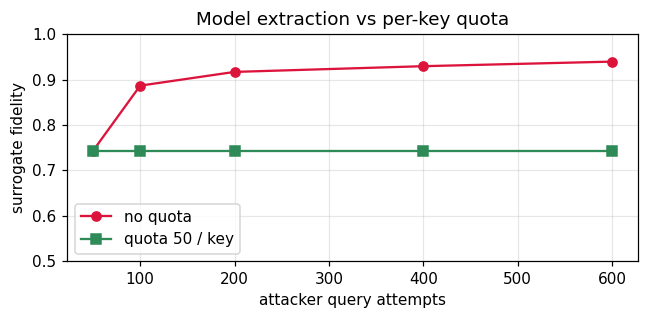

In [10]:
# (b) 모델 추출: 공격자가 공개 데이터(pool)로 질의 → 응답 라벨로 대리 모델 학습
def extract(api, budget, key="attacker-key-1"):
    got_X, got_y = [], []
    for start in range(0, budget, 25):
        q = X[pool[start:start + 25]]
        try:
            out = api.predict(key, q)
        except QuotaExceeded:
            break
        got_X.append(q); got_y.append(out.argmax(1) if out.ndim == 2 else out)
    Xs, ys = np.vstack(got_X), np.concatenate(got_y)
    sur = LogisticRegression(max_iter=2000).fit(Xs, ys)
    return len(Xs), (sur.predict(X[test]) == victim.predict(X[test])).mean()

budgets = [50, 100, 200, 400, 600]
open_api = [extract(ModelAPI(victim, "label"), b) for b in budgets]
quota_api = [extract(ModelAPI(victim, "label", quota=50), b) for b in budgets]
for b, (n1, f1), (n2, f2) in zip(budgets, open_api, quota_api):
    print(f"시도 {b:3d}회 | 제한 없음: 질의 {n1:3d} → 충실도 {f1:.1%} | 키당 50회 할당량: 질의 {n2:3d} → 충실도 {f2:.1%}")

plt.figure(figsize=(6, 3))
plt.plot(budgets, [f for _, f in open_api], "o-", c="crimson", label="no quota")
plt.plot(budgets, [f for _, f in quota_api], "s-", c="seagreen", label="quota 50 / key")
plt.xlabel("attacker query attempts"); plt.ylabel("surrogate fidelity"); plt.ylim(0.5, 1); plt.grid(alpha=.3); plt.legend()
plt.title("Model extraction vs per-key quota"); plt.tight_layout(); plt.show()

In [11]:
# (c) 할당량은 키를 여러 개 만들면 우회된다 → '키'가 아니라 '신원(계정)' 단위로 집계하고 경보
api = ModelAPI(victim, "label", quota=50)
owner = {}
for k in range(6):                                   # 공격자 1명이 키 6개 발급
    key = f"attacker-key-{k}"; owner[key] = "account-mallory"
    api.predict(key, X[pool[k * 50:(k + 1) * 50]])
for k in range(3):                                   # 정상 사용자 3명
    key = f"student-{k}"; owner[key] = f"account-student-{k}"
    api.predict(key, X[pool[:30]])

by_key = pd.Series(api.usage, name="queries")
by_identity = by_key.groupby(by_key.index.map(owner)).sum()
THRESHOLD = 200
print("키 단위 최대 사용량:", by_key.max(), "→ 키 단위 할당량(50)에는 걸리지 않음")
display(by_identity.to_frame().assign(alarm=lambda d: np.where(d.queries > THRESHOLD, "ALARM", "OK")))

키 단위 최대 사용량: 50 → 키 단위 할당량(50)에는 걸리지 않음


,queries,alarm
account-mallory,300,ALARM
account-student-0,30,OK
account-student-1,30,OK
account-student-2,30,OK


## 5. 1회차 데모 전체를 심층 방어 계층에 매핑 (슬라이드 4, 6)

In [12]:
layers = pd.DataFrame([
    ["정책, 절차 및 인식",        "Scoping Matrix로 대리권 범위 결정, 사람 검토(HITL) 절차", "B"],
    ["Identity & Access 관리",    "검증된 토큰으로 actor 결정, IAM actorId·namespace 조건, 신원 단위 할당량", "B, C"],
    ["인프라 보호",               "런타임 역할 최소 권한, 고객 관리형 키 정책", "C"],
    ["네트워크 및 엣지 보호",      "VPC·PrivateLink로 모델·메모리 호출을 사설망으로 (슬라이드 27-28, 데모 없음)", "-"],
    ["애플리케이션 보호",          "AgentCore Policy(Cedar)로 도구 호출 통제, 경계 표시·입력 필터", "A"],
    ["데이터 보호",               "PII 마스킹·해시 로그·보존 기간, 봉투 암호화, 출력 최소화", "C"],
    ["위협 탐지 및 사고 대응",      "감사 추적 5요소 + 탐지 규칙, 사용량 경보", "B, C"],
], columns=["방어 계층 (슬라이드 4)", "1회차 데모에서 본 통제", "데모"])
layers

,방어 계층 (슬라이드 4),1회차 데모에서 본 통제,데모
0,"정책, 절차 및 인식","Scoping Matrix로 대리권 범위 결정, 사람 검토(HITL) 절차",B
1,Identity & Access 관리,"검증된 토큰으로 actor 결정, IAM actorId·namespace 조건, 신원 단위 할당량","B, C"
2,인프라 보호,"런타임 역할 최소 권한, 고객 관리형 키 정책",C
3,네트워크 및 엣지 보호,"VPC·PrivateLink로 모델·메모리 호출을 사설망으로 (슬라이드 27-28, 데모 없음)",-
4,애플리케이션 보호,"AgentCore Policy(Cedar)로 도구 호출 통제, 경계 표시·입력 필터",A
5,데이터 보호,"PII 마스킹·해시 로그·보존 기간, 봉투 암호화, 출력 최소화",C
6,위협 탐지 및 사고 대응,"감사 추적 5요소 + 탐지 규칙, 사용량 경보","B, C"


## 정리
| 1회차 공격 | 무엇이 새나가나 | 이번 데모의 통제 | 교재 |
|---|---|---|---|
| 프롬프트·로그를 통한 민감정보 노출 | 질문 원문, 도구 결과 | 마스킹, 해시 로그, 보존 기간, Guardrails 민감정보 필터 | 20 |
| 저장 데이터 탈취 | 장기 기억 | CMK 봉투 암호화, 키 정책, 암호화 컨텍스트 | 20, 28 |
| 에이전트를 통한 다른 사용자 데이터 접근 | 다른 사용자의 이벤트·기억 | IAM 리소스 범위 + actorId·namespace 조건 + 명시적 Deny | 24~26 |
| 멤버십 추론 | 학습 데이터 포함 여부 | 출력 최소화(라벨만 반환) | 29, 30 |
| 모델 추출 | 모델 기능 자체 | 신원 단위 할당량 + 사용량 경보 | 29, 30 |

- 암호화는 **누가 읽을 수 있는가**를, IAM은 **누가 요청할 수 있는가**를, 출력 최소화와 할당량은 **요청해서 얼마나 얻을 수 있는가**를 줄입니다.
- 모든 통제는 *줄이는* 것이지 *없애는* 것이 아닙니다. 그래서 탐지(감사·경보)가 마지막 겹으로 남습니다.

**변형 실험**: `THRESHOLD`를 낮추면 정상 사용자도 경보에 걸리기 시작합니다. 오탐과 미탐 사이의 트레이드오프를 확인해 보세요. P3 정책의 `StringLike` 값을 `users/*`로 넓히면 어떤 요청이 다시 허용될까요?